In [1]:
import matplotlib.pyplot as plt

from superfv.initial_conditions import shu_osher
from superfv import run_multiple_simulations


In [2]:
N = 400
Nref = 10000

init_params = dict(ic=shu_osher, bcx=("free", "free"))
run_params = dict(t=0.178, allow_overshoot=True)

In [3]:
musclhancock = dict(p=1, use_MUSCL=True)
apriori = dict(use_ZS=True, adaptive_dt=True)
aposteriori = dict(use_MOOD=True, positivity_guard=False)
aposteriori_1rev = dict(fallback_cascade="muscl", max_revs=1, **aposteriori)
aposteriori_2revs = dict(fallback_cascade="muscl0", max_revs=2, **aposteriori)
aposteriori_3revs = dict(fallback_cascade="muscl0", max_revs=3, **aposteriori)

configs = {
    "ref": musclhancock,
    "MUSCL-Hancock": musclhancock,
    "ZS3": dict(p=3, **apriori),
    "ZS7": dict(p=7, **apriori),
    "MM3/1rev/no_NAD": dict(p=3, use_NAD=False, use_SED=False, **aposteriori_1rev),
    "MM7/1rev/no_NAD": dict(p=7, use_NAD=False, use_SED=False, **aposteriori_1rev),
    "MM3/1rev/rtol_1e-1": dict(p=3, rtol=1e-1, **aposteriori_1rev),
    "MM7/1rev/rtol_1e-1": dict(p=7, rtol=1e-1, **aposteriori_1rev),
    "MM3/1rev/rtol_0": dict(p=3, rtol=0, **aposteriori_1rev),
    "MM7/1rev/rtol_0": dict(p=7, rtol=0, **aposteriori_1rev),
}

In [4]:
sims = {}


def postprocess(name, sim):
    sims[name] = sim


run_multiple_simulations(
    {
        name: (
            dict(nx=Nref if name == "ref" else N, **init_params, **config),
            dict(
                time_integrator=(
                    "rk4"
                    if "RK4" in name
                    else "ssprk3"
                    if "RK3" in name
                    else "muscl_hancock"
                    if config.get("use_MUSCL", False)
                    else "match_p_up_to_ssprk3"
                ),
                **run_params,
            ),
        )
        for name, config in configs.items()
    },
    "/scratch/gpfs/jp7427/out/shu-osher/",
    postprocess=postprocess,
)

Loaded existing output for simulation 'ref' from '/scratch/gpfs/jp7427/out/shu-osher/ref'.
Loaded existing output for simulation 'MUSCL-Hancock' from '/scratch/gpfs/jp7427/out/shu-osher/MUSCL-Hancock'.
Loaded existing output for simulation 'ZS3' from '/scratch/gpfs/jp7427/out/shu-osher/ZS3'.
Loaded existing output for simulation 'ZS7' from '/scratch/gpfs/jp7427/out/shu-osher/ZS7'.
Loaded existing output for simulation 'MM3/1rev/no_NAD' from '/scratch/gpfs/jp7427/out/shu-osher/MM3/1rev/no_NAD'.
Loaded existing output for simulation 'MM7/1rev/no_NAD' from '/scratch/gpfs/jp7427/out/shu-osher/MM7/1rev/no_NAD'.
Loaded existing output for simulation 'MM3/1rev/rtol_1e-1' from '/scratch/gpfs/jp7427/out/shu-osher/MM3/1rev/rtol_1e-1'.
Loaded existing output for simulation 'MM7/1rev/rtol_1e-1' from '/scratch/gpfs/jp7427/out/shu-osher/MM7/1rev/rtol_1e-1'.
Loaded existing output for simulation 'MM3/1rev/rtol_0' from '/scratch/gpfs/jp7427/out/shu-osher/MM3/1rev/rtol_0'.
Loaded existing output for si

In [5]:
plt.rcParams['font.size'] = 14

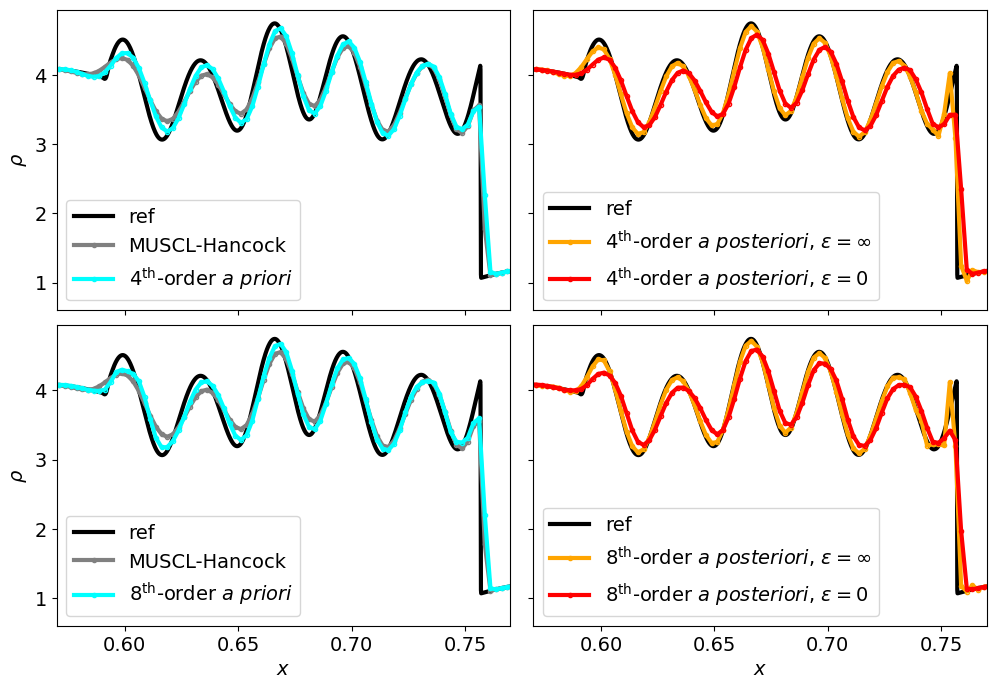

In [8]:
fig, axs = plt.subplots(2, 2, sharex=True, sharey=True, figsize=(12, 8))
axs[1, 0].set_xlabel(r"$x$")
axs[1, 1].set_xlabel(r"$x$")
axs[0, 0].set_ylabel(r"$\rho$")
axs[1, 0].set_ylabel(r"$\rho$")
axs[0, 0].set_xlim(0.57, 0.77)

cmap1 = plt.get_cmap("GnBu")
cmap2 = plt.get_cmap("OrRd")


def plot(name, ax, v, style=dict()):
    _style = dict(
        label=name,
        linestyle="-" if name == "ref" else "-",
        linewidth=3,
        markersize=3,
        marker="none" if name == "ref" else "o",
        mfc="none",
        alpha=1 if name == "ref" else 1,
    )
    _style.update(style)

    sim = sims[name]
    idx = sim.params.variable_index_map
    snapshot = sim.snapshot_history[-1]
    x = sim.mesh.centers[0]

    if v == "theta":
        q = _style.pop("multivar_func")(idx, sim.mesh, snapshot.theta)
    elif v == "cascade":
        q = snapshot.cascade_idx[0]
    else:
        q = snapshot.w[idx(v)]

    ax.plot(x, q.squeeze(), **_style)


plot("ref", axs[0, 0], "rho", dict(color="k"))
plot("MUSCL-Hancock", axs[0, 0], "rho", dict(color="grey"))
plot("ZS3", axs[0, 0], "rho", dict(color="cyan", label=r"$4^{\mathrm{th}}$-order $\mathit{a\ priori}$"))

plot("ref", axs[1, 0], "rho", dict(color="k"))
plot("MUSCL-Hancock", axs[1, 0], "rho", dict(color="grey"))
plot("ZS7", axs[1, 0], "rho", dict(color="cyan", label=r"$8^{\mathrm{th}}$-order $\mathit{a\ priori}$"))

plot("ref", axs[0, 1], "rho", dict(color="k"))
plot("MM3/1rev/no_NAD", axs[0, 1], "rho", dict(color="orange", label=r"$4^{\mathrm{th}}$-order $\mathit{a\ posteriori}$, $\varepsilon=\infty$"))
plot("MM3/1rev/rtol_0", axs[0, 1], "rho", dict(color="red", label=r"$4^{\mathrm{th}}$-order $\mathit{a\ posteriori}$, $\varepsilon=0$"))

plot("ref", axs[1, 1], "rho", dict(color="k"))
plot("MM7/1rev/no_NAD", axs[1, 1], "rho", dict(color="orange", label=r"$8^{\mathrm{th}}$-order $\mathit{a\ posteriori}$, $\varepsilon=\infty$"))
plot("MM7/1rev/rtol_0", axs[1, 1], "rho", dict(color="red", label=r"$8^{\mathrm{th}}$-order $\mathit{a\ posteriori}$, $\varepsilon=0$"))

axs[0, 0].legend()
axs[1, 0].legend()
axs[0, 1].legend()
axs[1, 1].legend()

plt.subplots_adjust(hspace=0.05, wspace=0.05)

fig.savefig("shu_osher_talk.pdf", bbox_inches="tight")